# Study Habits and Learning Preferences Across Age Groups


## 1. Import libraries and load data


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_name = "Study Habits and Learning Preferences Across Age Groups.csv"
df = pd.read_csv(file_name)

df.head()

,Timestamp,What is your age group?,How many hours do you devote to self-study each day?,How long does a typical study session last for you?,What time of the day do you prefer to study?,What do you mainly use your study tools for?,Which note-taking method do you prefer when studying?,What is the main reason for your note-taking preference?\n,How do you generally prefer to study? (Range),"If you were to study with others, what group size would you prefer? (Categories)","When trying to understand a difficult topic, which approach do you find more helpful? (Categories)","How often do you use video tutorials (e.g., YouTube, online course videos) to support your learning?",How often do you use blogs or written online articles to support your learning?,"When you need to reinforce or review something you are learning, which format do you usually prefer?"
0,2026/10/27 5:17:05 PM GMT,18-24,less than 30 minutes,Less than 30 mins,Night (after 9 pm),Researching and finding information,Both digitally and by hand,It helps me remember information better,Mostly alone,I would prefer not to study with others,Both are equally helpful,Rarely (less than once a month),Rarely (less than once a month),Neither (I use other resources)
1,2026/10/27 5:18:23 PM GMT,18-24,More than 5 hours,2-3 hours,Late morning (9 am-12 pm),Researching and finding information,By hand (pen and paper),It helps me remember information better,Mostly alone,With one other person,Studying alone,Sometimes (a few times a month),Never,Neither (I use other resources)
2,2026/10/27 5:22:47 PM GMT,18-24,1 - 2 hours,1-2 hours,Evening (5 pm-9 pm),Understanding difficult topics,Both digitally and by hand,It helps me concentrate,Always alone,I would prefer not to study with others,Studying alone,Sometimes (a few times a month),Rarely (less than once a month),Video tutorials
3,2026/10/28 2:08:09 AM GMT,18-24,3 - 4 hours,1-2 hours,Evening (5 pm-9 pm),Taking and organising notes,Both digitally and by hand,It helps me remember information better,Always alone,With one other person,Studying alone,Very often (several times a week or more),Never,Video tutorials
4,2026/11/10 3:53:52 PM GMT,18-24,1 - 2 hours,30-60 mins,Evening (5 pm-9 pm),Watching educational videos,By hand (pen and paper),It helps me stay organised,Mostly alone,"In a small group of 3-4 people, including myself",Studying alone,Sometimes (a few times a month),Sometimes (a few times a month),Both equally


In [3]:
n_responses = len(df)

df.shape

(32, 14)

In [4]:
df.describe()

,Timestamp,What is your age group?,How many hours do you devote to self-study each day?,How long does a typical study session last for you?,What time of the day do you prefer to study?,What do you mainly use your study tools for?,Which note-taking method do you prefer when studying?,What is the main reason for your note-taking preference?\n,How do you generally prefer to study? (Range),"If you were to study with others, what group size would you prefer? (Categories)","When trying to understand a difficult topic, which approach do you find more helpful? (Categories)","How often do you use video tutorials (e.g., YouTube, online course videos) to support your learning?",How often do you use blogs or written online articles to support your learning?,"When you need to reinforce or review something you are learning, which format do you usually prefer?"
count,32,32,32,32,32,32,32,32,32,32,32,32,32,32
unique,32,5,7,5,6,6,3,6,4,5,4,4,5,4
top,2026/10/27 5:17:05 PM GMT,18-24,1 - 2 hours,1-2 hours,Late morning (9 am-12 pm),Researching and finding information,Both digitally and by hand,It helps me remember information better,Mostly alone,"In a small group of 3-4 people, including myself",Studying alone,Sometimes (a few times a month),Rarely (less than once a month),Video tutorials
freq,1,17,12,14,8,10,15,20,17,20,13,14,9,12


In [5]:
os.makedirs("figures", exist_ok=True)

In [6]:
# Builds the file name for a chart from its number and title, for example
# plot_file_name(9, "Daily self-study time") gives "figures/09_Daily_self-study_time.png"
def plot_file_name(number, title):
    name = title.replace(" ", "_")
    return f"figures/{number:02d}_{name}.png"

## 2. Check and prepare data


### 2.1 Column names


In [7]:
df.columns.tolist()

['Timestamp',
 'What is your age group?',
 'How many hours do you devote to self-study each day?',
 'How long does a typical study session last for you?',
 'What time of the day do you prefer to study?',
 'What do you mainly use your study tools for?',
 'Which note-taking method do you prefer when studying?',
 'What is the main reason for your note-taking preference?\n',
 'How do you generally prefer to study? (Range)',
 'If you were to study with others, what group size would you prefer? (Categories)',
 'When trying to understand a difficult topic, which approach do you find more helpful? (Categories)',
 'How often do you use video tutorials (e.g., YouTube, online course videos) to support your learning?',
 'How often do you use blogs or written online articles to support your learning?',
 'When you need to reinforce or review something you are learning, which format do you usually prefer?']

### 2.2 Drop and rename columns


In [8]:
# We do not analyse the time of each response, so drop the timestamp
df.drop(columns=["Timestamp"], inplace=True)

df.columns.tolist()

['What is your age group?',
 'How many hours do you devote to self-study each day?',
 'How long does a typical study session last for you?',
 'What time of the day do you prefer to study?',
 'What do you mainly use your study tools for?',
 'Which note-taking method do you prefer when studying?',
 'What is the main reason for your note-taking preference?\n',
 'How do you generally prefer to study? (Range)',
 'If you were to study with others, what group size would you prefer? (Categories)',
 'When trying to understand a difficult topic, which approach do you find more helpful? (Categories)',
 'How often do you use video tutorials (e.g., YouTube, online course videos) to support your learning?',
 'How often do you use blogs or written online articles to support your learning?',
 'When you need to reinforce or review something you are learning, which format do you usually prefer?']

In [9]:
# New short names, in the same order as the original columns, we can use rename() with old and new names in a dictionary
df.columns = [
    "age_group",
    "daily_study",
    "session_length",
    "study_time",
    "tool_purpose",
    "note_method",
    "note_reason",
    "study_preference",
    "group_size",
    "difficult_topic",
    "video_use",
    "article_use",
    "review_format",
]

df.columns.tolist()

['age_group',
 'daily_study',
 'session_length',
 'study_time',
 'tool_purpose',
 'note_method',
 'note_reason',
 'study_preference',
 'group_size',
 'difficult_topic',
 'video_use',
 'article_use',
 'review_format']

### 2.3 Missing answers


In [10]:
df.isna().sum()

age_group           0
daily_study         0
session_length      0
study_time          0
tool_purpose        0
note_method         0
note_reason         0
study_preference    0
group_size          0
difficult_topic     0
video_use           0
article_use         0
review_format       0
dtype: int64

In [11]:
df.describe()

,age_group,daily_study,session_length,study_time,tool_purpose,note_method,note_reason,study_preference,group_size,difficult_topic,video_use,article_use,review_format
count,32,32,32,32,32,32,32,32,32,32,32,32,32
unique,5,7,5,6,6,3,6,4,5,4,4,5,4
top,18-24,1 - 2 hours,1-2 hours,Late morning (9 am-12 pm),Researching and finding information,Both digitally and by hand,It helps me remember information better,Mostly alone,"In a small group of 3-4 people, including myself",Studying alone,Sometimes (a few times a month),Rarely (less than once a month),Video tutorials
freq,17,12,14,8,10,15,20,17,20,13,14,9,12


### 2.4 Duplicate rows


In [12]:
# Rows with the same answers are only possible matches
# Different people can give the same answers, so we keep them
df.duplicated().value_counts()

False    32
Name: count, dtype: int64

## 3. Set variable types and category order


### 3.1 Answer options from the questionnaire


In [13]:
# Ordered answer options, in the same order as the questionnaire
age_levels = ["18-24", "25-30", "31-35", "36-40", "more than 40"]

daily_study_levels = [
    "less than 30 minutes",
    "30 minutes to 1 hour",
    "1 - 2 hours",
    "2 - 3 hours",
    "3 - 4 hours",
    "4 - 5 hours",
    "More than 5 hours",
]

session_levels = [
    "Less than 30 mins",
    "30-60 mins",
    "1-2 hours",
    "2-3 hours",
    "More than 3 hours",
]

preference_levels = [
    "Always alone",
    "Mostly alone",
    "Equally alone and with others",
    "Mostly with others",
    "Always with others",
]

# Video and article questions use the same scale
frequency_levels = [
    "Never",
    "Rarely (less than once a month)",
    "Sometimes (a few times a month)",
    "Often (weekly)",
    "Very often (several times a week or more)",
]

In [14]:
# Unordered answer options, in the same order as the questionnaire
time_levels = [
    "Early morning (5 am-9 am)",
    "Late morning (9 am-12 pm)",
    "Afternoon (12 pm-5 pm)",
    "Evening (5 pm-9 pm)",
    "Night (after 9 pm)",
    "No fixed preference",
]

tool_levels = [
    "Reading lecture notes",
    "Watching educational videos",
    "Taking and organising notes",
    "Practising exercises or solving problems",
    "Researching and finding information",
    "Understanding difficult topics",
]

note_method_levels = [
    "Digitally",
    "By hand (pen and paper)",
    "Both digitally and by hand",
    "I prefer not to take notes",
]

note_reason_levels = [
    "It helps me remember information better",
    "It saves time",
    "It helps me stay organised",
    "It is more convenient",
    "It helps me concentrate",
    "I find taking notes unnecessary",
]

group_size_levels = [
    "With one other person",
    "In a small group of 3-4 people, including myself",
    "In a larger group of 5 or more people, including myself",
    "No preference for group size",
    "I would prefer not to study with others",
]

difficult_topic_levels = [
    "Studying alone",
    "Studying with others",
    "Both are equally helpful",
    "I have not tried both approaches enough to compare",
]

review_levels = [
    "Video tutorials",
    "Blogs or written articles",
    "Both equally",
    "Neither (I use other resources)",
]

### 3.2 Ordinal and nominal types


In [15]:
# One dictionary gives each column its type, like dtype={...} in pd.read_csv
df = df.astype(
    {
        # Ordinal variables: the answers have a natural order
        "age_group": pd.CategoricalDtype(categories=age_levels, ordered=True),
        "daily_study": pd.CategoricalDtype(categories=daily_study_levels, ordered=True),
        "session_length": pd.CategoricalDtype(categories=session_levels, ordered=True),
        "study_preference": pd.CategoricalDtype(
            categories=preference_levels, ordered=True
        ),
        "video_use": pd.CategoricalDtype(categories=frequency_levels, ordered=True),
        "article_use": pd.CategoricalDtype(categories=frequency_levels, ordered=True),
        # Nominal variables: no natural order, the list order is only for display
        # Time of day follows the day, "No fixed preference" stays at the end
        "study_time": pd.CategoricalDtype(categories=time_levels, ordered=False),
        "tool_purpose": pd.CategoricalDtype(categories=tool_levels, ordered=False),
        "note_method": pd.CategoricalDtype(
            categories=note_method_levels, ordered=False
        ),
        "note_reason": pd.CategoricalDtype(
            categories=note_reason_levels, ordered=False
        ),
        "group_size": pd.CategoricalDtype(categories=group_size_levels, ordered=False),
        "difficult_topic": pd.CategoricalDtype(
            categories=difficult_topic_levels, ordered=False
        ),
        "review_format": pd.CategoricalDtype(categories=review_levels, ordered=False),
    }
)

In [16]:
# Check that no answers became missing after setting the types
df.isna().sum()

age_group           0
daily_study         0
session_length      0
study_time          0
tool_purpose        0
note_method         0
note_reason         0
study_preference    0
group_size          0
difficult_topic     0
video_use           0
article_use         0
review_format       0
dtype: int64

## 4. Sample overview and key individual variables


In [17]:
# Summary of every question: top is the most common answer (mode), freq is its count
df.describe()

,age_group,daily_study,session_length,study_time,tool_purpose,note_method,note_reason,study_preference,group_size,difficult_topic,video_use,article_use,review_format
count,32,32,32,32,32,32,32,32,32,32,32,32,32
unique,5,7,5,6,6,3,6,4,5,4,4,5,4
top,18-24,1 - 2 hours,1-2 hours,Late morning (9 am-12 pm),Researching and finding information,Both digitally and by hand,It helps me remember information better,Mostly alone,"In a small group of 3-4 people, including myself",Studying alone,Sometimes (a few times a month),Rarely (less than once a month),Video tutorials
freq,17,12,14,8,10,15,20,17,20,13,14,9,12


### 4.1 Age group


In [18]:
age_counts = df["age_group"].value_counts(sort=False)
age_percent = df["age_group"].value_counts(sort=False, normalize=True) * 100

age_table = pd.DataFrame({"count": age_counts, "percent": age_percent.round(1)})
age_table

,count,percent
age_group,,
18-24,17,53.1
25-30,7,21.9
31-35,1,3.1
36-40,3,9.4
more than 40,4,12.5


In [19]:
age_counts.max()

np.int64(17)

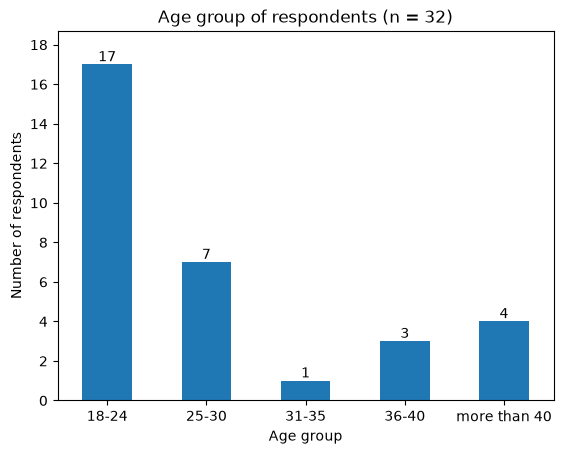

In [20]:
# Purpose: show how many respondents are in each age group
fig, ax = plt.subplots()
age_counts.plot.bar(ax=ax, rot=0)
ax.bar_label(ax.containers[0])
ax.margins(y=0.1)
# Whole numbers on the count axis, one tick every 2 people
# We use 20 because the largest count is 17
ax.set_yticks(range(0, 20, 2))
ax.set_title(f"Age group of respondents (n = {n_responses})")
ax.set_xlabel("Age group")
ax.set_ylabel("Number of respondents")

fig.savefig(plot_file_name(1, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

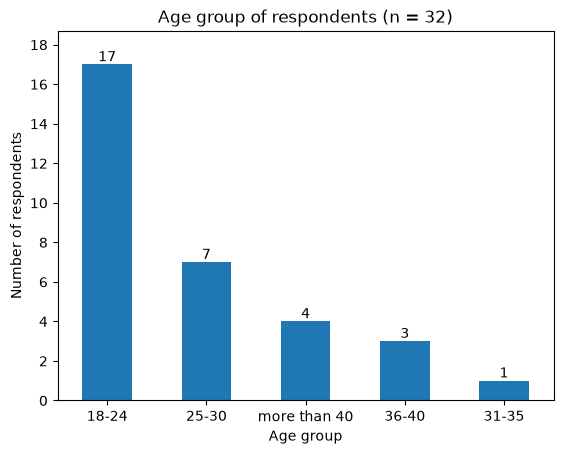

In [21]:
# Purpose: show how many respondents are in each age group (sort from number of records on each age)
fig, ax = plt.subplots()
age_counts.sort_values(ascending=False).plot.bar(ax=ax, rot=0)
ax.bar_label(ax.containers[0])
ax.margins(y=0.1)
# Whole numbers on the count axis, one tick every 2 people
# We use 20 because the largest count is 17
ax.set_yticks(range(0, 20, 2))
ax.set_title(f"Age group of respondents (n = {n_responses})")
ax.set_xlabel("Age group")
ax.set_ylabel("Number of respondents")

fig.savefig(plot_file_name(8, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 4.2 Two age groups for the comparisons


In [22]:
# 31-35, 36-40 and more than 40 are too small to compare on their own
# So we compare 18-24 with everyone aged 25 and over
age_band_names = {
    "18-24": "18-24",
    "25-30": "25 and over",
    "31-35": "25 and over",
    "36-40": "25 and over",
    "more than 40": "25 and over",
}
df["age_band"] = df["age_group"].map(age_band_names)

band_levels = ["18-24", "25 and over"]
df["age_band"] = df["age_band"].astype(
    pd.CategoricalDtype(categories=band_levels, ordered=True)
)

In [23]:
band_counts = df["age_band"].value_counts(sort=False)
band_percent = df["age_band"].value_counts(sort=False, normalize=True) * 100

band_table = pd.DataFrame({"count": band_counts, "percent": band_percent.round(1)})
band_table

,count,percent
age_band,,
18-24,17,53.1
25 and over,15,46.9


In [24]:
# Age group labels with group sizes, used in the comparison charts
age_labels = []
for band in band_levels:
    age_labels.append(f"{band} (n={band_counts[band]})")

age_labels

['18-24 (n=17)', '25 and over (n=15)']

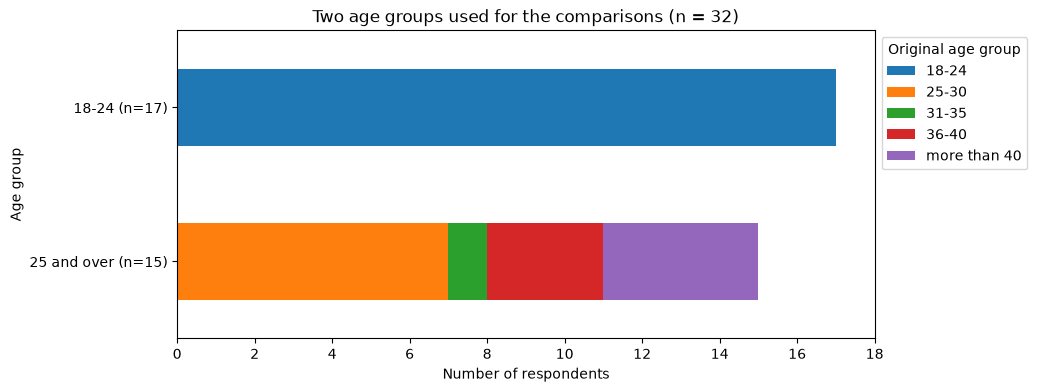

In [25]:
# Purpose: show the two comparison groups and which age groups are inside each
chart_table = pd.crosstab(df["age_band"], df["age_group"])

fig, ax = plt.subplots(figsize=(9, 4))
chart_table.plot.barh(stacked=True, ax=ax)
ax.invert_yaxis()
ax.set_yticklabels(age_labels)
ax.set_xlim(0, band_counts.max() + 1)
ax.set_title(f"Two age groups used for the comparisons (n = {n_responses})")
ax.set_xlabel("Number of respondents")
ax.set_ylabel("Age group")
ax.legend(title="Original age group", bbox_to_anchor=(1.0, 1.0), loc="upper left")

fig.savefig(plot_file_name(2, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 4.3 Daily self-study time


In [26]:
daily_counts = df["daily_study"].value_counts(sort=False)
daily_percent = df["daily_study"].value_counts(sort=False, normalize=True) * 100

daily_table = pd.DataFrame({"count": daily_counts, "percent": daily_percent.round(1)})
daily_table

,count,percent
daily_study,,
less than 30 minutes,4,12.5
30 minutes to 1 hour,6,18.8
1 - 2 hours,12,37.5
2 - 3 hours,3,9.4
3 - 4 hours,4,12.5
4 - 5 hours,1,3.1
More than 5 hours,2,6.2


In [27]:
daily_counts.index.tolist()

['less than 30 minutes',
 '30 minutes to 1 hour',
 '1 - 2 hours',
 '2 - 3 hours',
 '3 - 4 hours',
 '4 - 5 hours',
 'More than 5 hours']

In [28]:
# Short names for the charts, in the same order as the list above
daily_short = [
    "< 30 m",
    "30 m-1 h",
    "1-2 h",
    "2-3 h",
    "3-4 h",
    "4-5 h",
    "> 5 h",
]

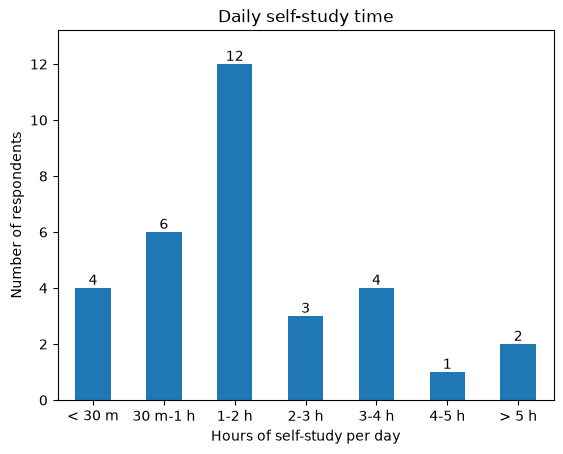

In [29]:
# Purpose: show how much time respondents spend on self-study each day
fig, ax = plt.subplots()
daily_counts.plot.bar(ax=ax, rot=0)
ax.set_xticklabels(daily_short)
ax.bar_label(ax.containers[0])
ax.margins(y=0.1)
ax.set_title("Daily self-study time")
ax.set_xlabel("Hours of self-study per day")
ax.set_ylabel("Number of respondents")

fig.savefig(plot_file_name(9, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 4.4 Study preference: alone or with others


In [30]:
preference_counts = df["study_preference"].value_counts(sort=False)
preference_percent = (
    df["study_preference"].value_counts(sort=False, normalize=True) * 100
)

preference_table = pd.DataFrame(
    {"count": preference_counts, "percent": preference_percent.round(1)}
)
preference_table

,count,percent
study_preference,,
Always alone,8,25.0
Mostly alone,17,53.1
Equally alone and with others,4,12.5
Mostly with others,3,9.4
Always with others,0,0.0


In [31]:
preference_counts.index.tolist()

['Always alone',
 'Mostly alone',
 'Equally alone and with others',
 'Mostly with others',
 'Always with others']

In [32]:
# Short names for the charts, in the same order as the list above
preference_short = [
    "Always alone",
    "Mostly alone",
    "Both equally",
    "Mostly with others",
    "Always with others",
]

In [33]:
preference_counts.max()

np.int64(17)

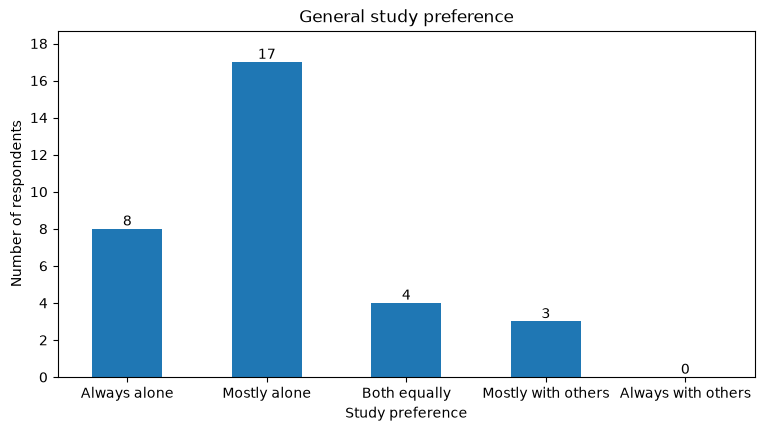

In [34]:
# Purpose: show whether respondents generally prefer to study alone or with others
fig, ax = plt.subplots(figsize=(9, 4.5))
preference_counts.plot.bar(ax=ax, rot=0)
ax.set_xticklabels(preference_short)
ax.bar_label(ax.containers[0])
ax.margins(y=0.1)
# Whole numbers on the count axis, one tick every 2 people
# We use 20 because the largest count is 17
ax.set_yticks(range(0, 20, 2))
ax.set_title("General study preference")
ax.set_xlabel("Study preference")
ax.set_ylabel("Number of respondents")

fig.savefig(plot_file_name(10, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

## 5. Research question 1: study duration and timing


### 5.1 Daily self-study time by age group


In [35]:
# Raw counts, so the percentages can be checked
daily_by_age = pd.crosstab(df["age_band"], df["daily_study"], margins=True)
daily_by_age

daily_study,less than 30 minutes,30 minutes to 1 hour,1 - 2 hours,2 - 3 hours,3 - 4 hours,4 - 5 hours,More than 5 hours,All
age_band,,,,,,,,
18-24,3,4,5,1,3,0,1,17
25 and over,1,2,7,2,1,1,1,15
All,4,6,12,3,4,1,2,32


In [36]:
# Percentages are within each age group (each row adds up to 100)
daily_by_age_pct = (
    pd.crosstab(df["age_band"], df["daily_study"], normalize="index") * 100
)
daily_by_age_pct.round(1)

daily_study,less than 30 minutes,30 minutes to 1 hour,1 - 2 hours,2 - 3 hours,3 - 4 hours,4 - 5 hours,More than 5 hours
age_band,,,,,,,
18-24,17.6,23.5,29.4,5.9,17.6,0.0,5.9
25 and over,6.7,13.3,46.7,13.3,6.7,6.7,6.7


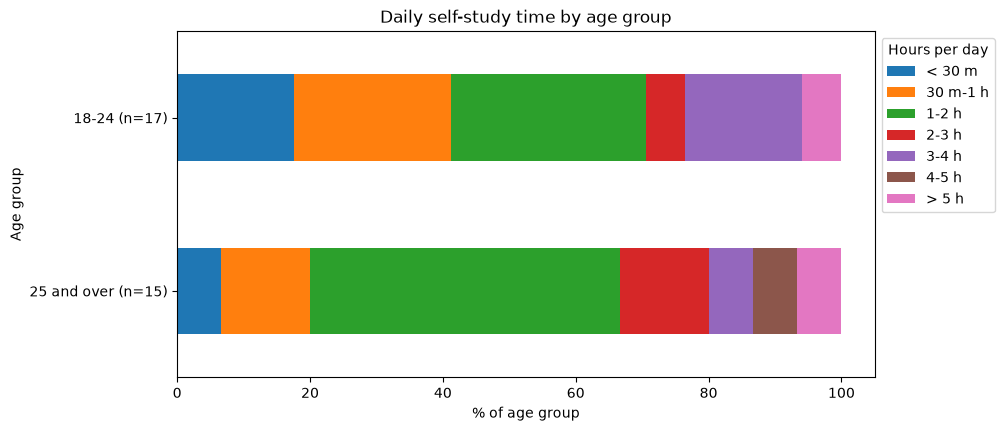

In [37]:
# Purpose: compare daily self-study time across age groups
fig, ax = plt.subplots(figsize=(9, 4.5))
daily_by_age_pct.plot.barh(stacked=True, ax=ax)
# daily_by_age_pct.plot.barh(stacked=True, ax=ax, colormap="viridis")
ax.invert_yaxis()
ax.set_yticklabels(age_labels)
ax.set_title("Daily self-study time by age group")
ax.set_xlabel("% of age group")
ax.set_ylabel("Age group")
ax.legend(
    daily_short, title="Hours per day", bbox_to_anchor=(1.0, 1.0), loc="upper left"
)

fig.savefig(plot_file_name(11, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 5.2 Typical session length


In [38]:
session_counts = df["session_length"].value_counts(sort=False)
session_percent = df["session_length"].value_counts(sort=False, normalize=True) * 100

session_table = pd.DataFrame(
    {"count": session_counts, "percent": session_percent.round(1)}
)
session_table

,count,percent
session_length,,
Less than 30 mins,4,12.5
30-60 mins,7,21.9
1-2 hours,14,43.8
2-3 hours,5,15.6
More than 3 hours,2,6.2


In [39]:
session_by_age = pd.crosstab(df["age_band"], df["session_length"], margins=True)
session_by_age

session_length,Less than 30 mins,30-60 mins,1-2 hours,2-3 hours,More than 3 hours,All
age_band,,,,,,
18-24,3,3,9,1,1,17
25 and over,1,4,5,4,1,15
All,4,7,14,5,2,32


In [40]:
session_by_age_pct = (
    pd.crosstab(df["age_band"], df["session_length"], normalize="index") * 100
)
session_by_age_pct.round(1)

session_length,Less than 30 mins,30-60 mins,1-2 hours,2-3 hours,More than 3 hours
age_band,,,,,
18-24,17.6,17.6,52.9,5.9,5.9
25 and over,6.7,26.7,33.3,26.7,6.7


In [41]:
session_counts.index.tolist()

['Less than 30 mins',
 '30-60 mins',
 '1-2 hours',
 '2-3 hours',
 'More than 3 hours']

In [42]:
# Short names for the charts, in the same order as the list above
session_short = [
    "< 30 m",
    "30-60 m",
    "1-2 h",
    "2-3 h",
    "> 3 h",
]

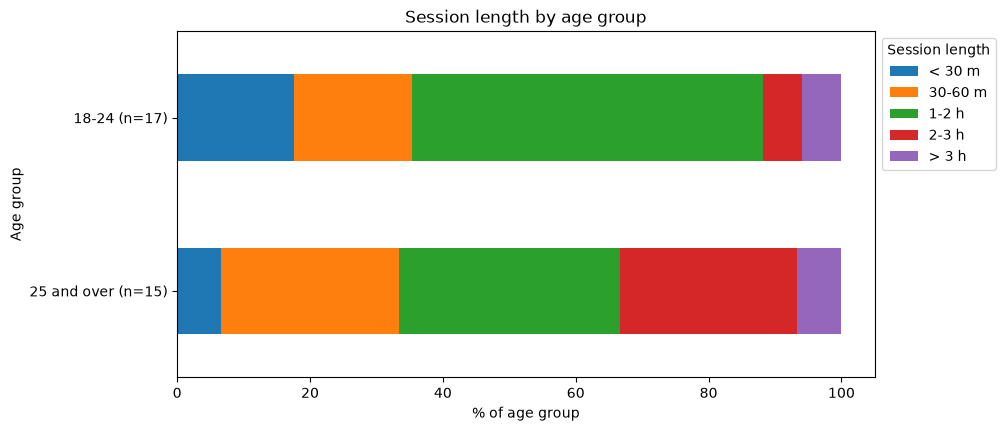

In [43]:
# Purpose: compare typical session length across age groups
fig, ax = plt.subplots(figsize=(9, 4.5))
session_by_age_pct.plot.barh(stacked=True, ax=ax)
ax.invert_yaxis()
ax.set_yticklabels(age_labels)
ax.set_title("Session length by age group")
ax.set_xlabel("% of age group")
ax.set_ylabel("Age group")
ax.legend(
    session_short, title="Session length", bbox_to_anchor=(1.0, 1.0), loc="upper left"
)

fig.savefig(plot_file_name(12, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 5.3 Preferred time of day


In [44]:
time_counts = df["study_time"].value_counts(sort=False)
time_percent = df["study_time"].value_counts(sort=False, normalize=True) * 100

time_table = pd.DataFrame({"count": time_counts, "percent": time_percent.round(1)})
time_table

,count,percent
study_time,,
Early morning (5 am-9 am),1,3.1
Late morning (9 am-12 pm),8,25.0
Afternoon (12 pm-5 pm),7,21.9
Evening (5 pm-9 pm),6,18.8
Night (after 9 pm),5,15.6
No fixed preference,5,15.6


In [45]:
time_by_age = pd.crosstab(df["age_band"], df["study_time"], margins=True)
time_by_age

study_time,Early morning (5 am-9 am),Late morning (9 am-12 pm),Afternoon (12 pm-5 pm),Evening (5 pm-9 pm),Night (after 9 pm),No fixed preference,All
age_band,,,,,,,
18-24,0,6,4,4,2,1,17
25 and over,1,2,3,2,3,4,15
All,1,8,7,6,5,5,32


In [46]:
time_by_age_pct = pd.crosstab(df["age_band"], df["study_time"], normalize="index") * 100
time_by_age_pct.round(1)

study_time,Early morning (5 am-9 am),Late morning (9 am-12 pm),Afternoon (12 pm-5 pm),Evening (5 pm-9 pm),Night (after 9 pm),No fixed preference
age_band,,,,,,
18-24,0.0,35.3,23.5,23.5,11.8,5.9
25 and over,6.7,13.3,20.0,13.3,20.0,26.7


In [47]:
time_counts.index.tolist()

['Early morning (5 am-9 am)',
 'Late morning (9 am-12 pm)',
 'Afternoon (12 pm-5 pm)',
 'Evening (5 pm-9 pm)',
 'Night (after 9 pm)',
 'No fixed preference']

In [48]:
# Short names for the charts, in the same order as the list above
time_short = [
    "5-9 am",
    "9 am-12 pm",
    "12-5 pm",
    "5-9 pm",
    "After 9 pm",
    "No fixed time",
]

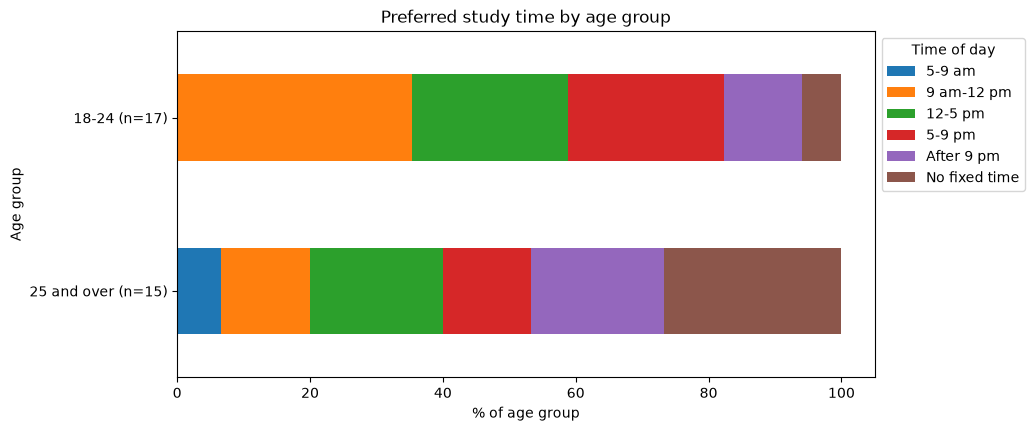

In [49]:
# Purpose: compare the preferred time of day across age groups
fig, ax = plt.subplots(figsize=(9, 4.5))
time_by_age_pct.plot.barh(stacked=True, ax=ax)
ax.invert_yaxis()
ax.set_yticklabels(age_labels)
ax.set_title("Preferred study time by age group")
ax.set_xlabel("% of age group")
ax.set_ylabel("Age group")
ax.legend(time_short, title="Time of day", bbox_to_anchor=(1.0, 1.0), loc="upper left")

fig.savefig(plot_file_name(13, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 5.4 All three routines together


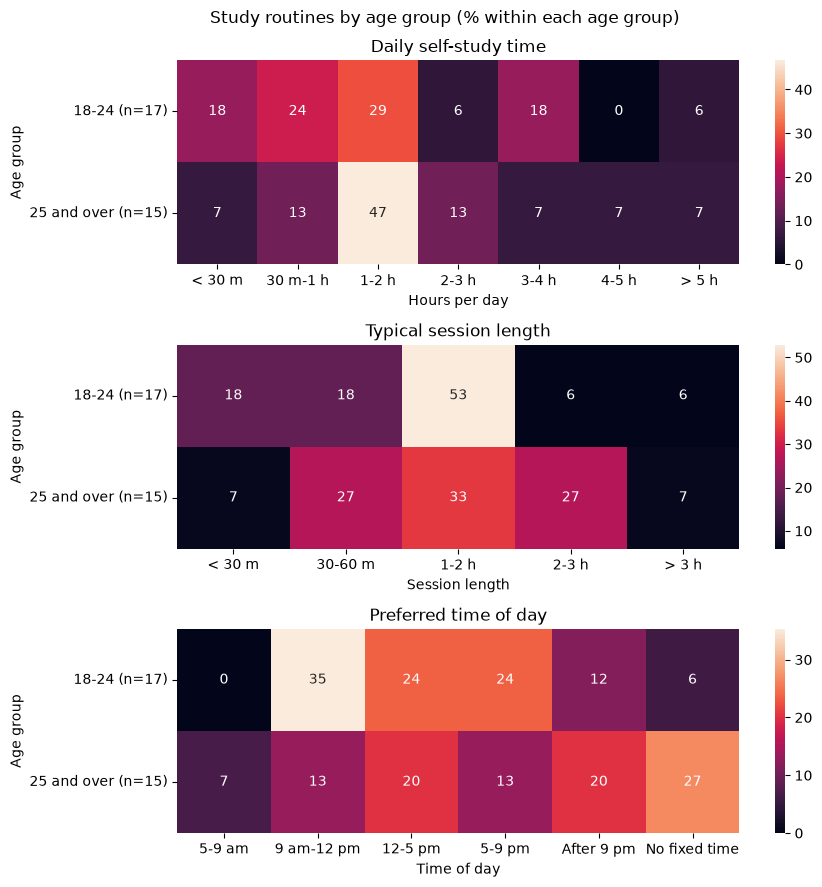

In [50]:
# Purpose: show the three study routine questions by age group in one figure
fig, axes = plt.subplots(3, 1, figsize=(9, 9))

sns.heatmap(daily_by_age_pct, annot=True, fmt=".0f", ax=axes[0])
axes[0].set_xticklabels(daily_short, rotation=0)
axes[0].set_yticklabels(age_labels, rotation=0)
axes[0].set_title("Daily self-study time")
axes[0].set_xlabel("Hours per day")
axes[0].set_ylabel("Age group")

sns.heatmap(session_by_age_pct, annot=True, fmt=".0f", ax=axes[1])
axes[1].set_xticklabels(session_short, rotation=0)
axes[1].set_yticklabels(age_labels, rotation=0)
axes[1].set_title("Typical session length")
axes[1].set_xlabel("Session length")
axes[1].set_ylabel("Age group")

sns.heatmap(time_by_age_pct, annot=True, fmt=".0f", ax=axes[2])
axes[2].set_xticklabels(time_short, rotation=0)
axes[2].set_yticklabels(age_labels, rotation=0)
axes[2].set_title("Preferred time of day")
axes[2].set_xlabel("Time of day")
axes[2].set_ylabel("Age group")

fig.suptitle("Study routines by age group (% within each age group)")

# Stop the three parts from overlapping
fig.tight_layout()

fig.savefig(plot_file_name(3, fig.get_suptitle()), dpi=300, bbox_inches="tight")
plt.show()

## 6. Research question 2: study tools and note-taking


### 6.1 Main use of study tools


In [51]:
# The question asks what tools are used for, not which devices or apps
# Sorted from most to least common
tool_counts = df["tool_purpose"].value_counts()
tool_percent = df["tool_purpose"].value_counts(normalize=True) * 100

tool_table = pd.DataFrame({"count": tool_counts, "percent": tool_percent.round(1)})
tool_table

,count,percent
tool_purpose,,
Researching and finding information,10,31.2
Watching educational videos,6,18.8
Understanding difficult topics,6,18.8
Reading lecture notes,4,12.5
Practising exercises or solving problems,4,12.5
Taking and organising notes,2,6.2


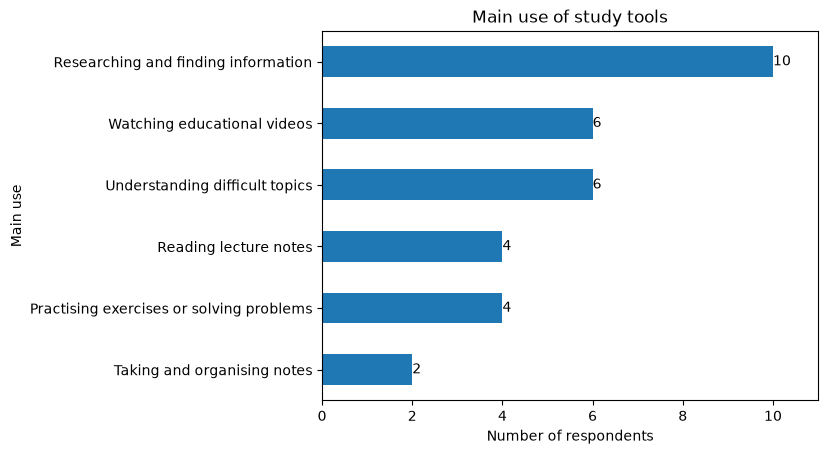

In [52]:
# Purpose: show what respondents mainly use their study tools for
fig, ax = plt.subplots()
tool_counts.plot.barh(ax=ax)
ax.invert_yaxis()
ax.bar_label(ax.containers[0])
ax.margins(x=0.1)
ax.set_title("Main use of study tools")
ax.set_xlabel("Number of respondents")
ax.set_ylabel("Main use")

fig.savefig(plot_file_name(14, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 6.2 Note-taking method


In [53]:
# "Both digitally and by hand" is one answer, we do not split it
method_counts = df["note_method"].value_counts(sort=False)
method_percent = df["note_method"].value_counts(sort=False, normalize=True) * 100

method_table = pd.DataFrame(
    {"count": method_counts, "percent": method_percent.round(1)}
)
method_table

,count,percent
note_method,,
Digitally,7,21.9
By hand (pen and paper),10,31.2
Both digitally and by hand,15,46.9
I prefer not to take notes,0,0.0


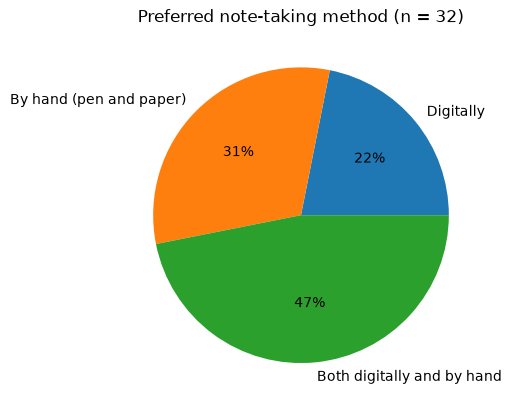

In [54]:
# Purpose: show how far respondents prefer digital notes or pen and paper
# A pie cannot show an empty slice, so we leave out options nobody chose
chart_counts = method_counts[method_counts > 0]

fig, ax = plt.subplots()
chart_counts.plot.pie(ax=ax, autopct="%1.0f%%", label="")
ax.set_title(f"Preferred note-taking method (n = {n_responses})")

fig.savefig(plot_file_name(15, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 6.3 Main reason for the note-taking preference


In [55]:
reason_counts = df["note_reason"].value_counts()
reason_percent = df["note_reason"].value_counts(normalize=True) * 100

reason_table = pd.DataFrame(
    {"count": reason_counts, "percent": reason_percent.round(1)}
)
reason_table

,count,percent
note_reason,,
It helps me remember information better,20,62.5
It helps me stay organised,6,18.8
It is more convenient,2,6.2
It helps me concentrate,2,6.2
It saves time,1,3.1
I find taking notes unnecessary,1,3.1


In [56]:
method_by_reason = pd.crosstab(df["note_method"], df["note_reason"], margins=True)
method_by_reason

note_reason,It helps me remember information better,It saves time,It helps me stay organised,It is more convenient,It helps me concentrate,I find taking notes unnecessary,All
note_method,,,,,,,
Digitally,3,0,1,2,0,1,7
By hand (pen and paper),9,0,1,0,0,0,10
Both digitally and by hand,8,1,4,0,2,0,15
All,20,1,6,2,2,1,32


In [57]:
df["note_reason"].cat.categories.tolist()

['It helps me remember information better',
 'It saves time',
 'It helps me stay organised',
 'It is more convenient',
 'It helps me concentrate',
 'I find taking notes unnecessary']

In [58]:
# Short names for the charts, in the same order as the list above
reason_short = [
    "Remember better",
    "Saves time",
    "Stay organised",
    "More convenient",
    "Concentrate",
    "Notes unnecessary",
]

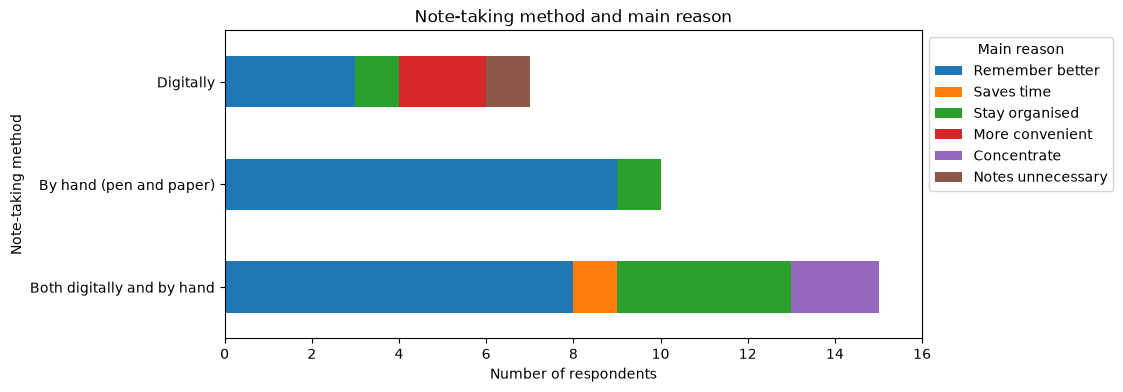

In [59]:
# Purpose: show how many respondents use each method and their main reason
chart_table = pd.crosstab(df["note_method"], df["note_reason"])

fig, ax = plt.subplots(figsize=(9, 4))
chart_table.plot.barh(stacked=True, ax=ax)
ax.invert_yaxis()
ax.set_xlim(0, method_counts.max() + 1)
ax.set_title("Note-taking method and main reason")
ax.set_xlabel("Number of respondents")
ax.set_ylabel("Note-taking method")
ax.legend(
    reason_short, title="Main reason", bbox_to_anchor=(1.0, 1.0), loc="upper left"
)

fig.savefig(plot_file_name(4, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

## 7. Research question 3: individual and group study


### 7.1 Study preference by age group


In [60]:
# Raw counts, dropna=False keeps answer options that nobody chose
preference_by_age = pd.crosstab(
    df["age_band"], df["study_preference"], margins=True, dropna=False
)
preference_by_age

study_preference,Always alone,Mostly alone,Equally alone and with others,Mostly with others,Always with others,All
age_band,,,,,,
18-24,5,8,2,2,0,17
25 and over,3,9,2,1,0,15
All,8,17,4,3,0,32


In [61]:
preference_by_age_pct = (
    pd.crosstab(df["age_band"], df["study_preference"], normalize="index", dropna=False)
    * 100
)
preference_by_age_pct.round(1)

study_preference,Always alone,Mostly alone,Equally alone and with others,Mostly with others,Always with others
age_band,,,,,
18-24,29.4,47.1,11.8,11.8,0.0
25 and over,20.0,60.0,13.3,6.7,0.0


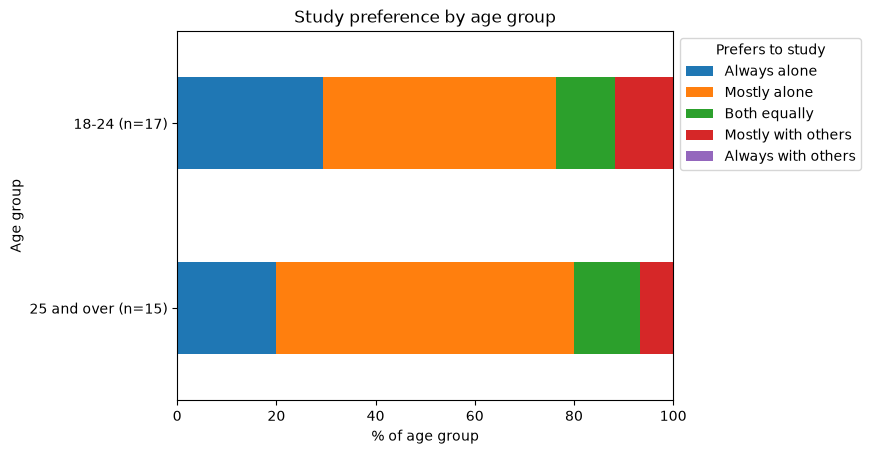

In [62]:
# Purpose: compare study alone or with others across age groups
fig, ax = plt.subplots()
preference_by_age_pct.plot.barh(stacked=True, ax=ax)
ax.invert_yaxis()
ax.set_yticklabels(age_labels)
ax.set_title("Study preference by age group")
ax.set_xlabel("% of age group")
ax.set_ylabel("Age group")
ax.legend(
    preference_short,
    title="Prefers to study",
    bbox_to_anchor=(1.0, 1.0),
    loc="upper left",
)

fig.savefig(plot_file_name(5, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 7.2 Preferred group size


In [63]:
# This is a "what if" question, it does not show real group study
group_counts = df["group_size"].value_counts(sort=False)
group_percent = df["group_size"].value_counts(sort=False, normalize=True) * 100

group_table = pd.DataFrame({"count": group_counts, "percent": group_percent.round(1)})
group_table

,count,percent
group_size,,
With one other person,5,15.6
"In a small group of 3-4 people, including myself",20,62.5
"In a larger group of 5 or more people, including myself",1,3.1
No preference for group size,2,6.2
I would prefer not to study with others,4,12.5


### 7.3 Approach for a difficult topic


In [64]:
difficult_counts = df["difficult_topic"].value_counts(sort=False)
difficult_percent = df["difficult_topic"].value_counts(sort=False, normalize=True) * 100

difficult_table = pd.DataFrame(
    {"count": difficult_counts, "percent": difficult_percent.round(1)}
)
difficult_table

,count,percent
difficult_topic,,
Studying alone,13,40.6
Studying with others,8,25.0
Both are equally helpful,8,25.0
I have not tried both approaches enough to compare,3,9.4


In [65]:
preference_by_difficult = pd.crosstab(
    df["study_preference"], df["difficult_topic"], margins=True, dropna=False
)
preference_by_difficult

difficult_topic,Studying alone,Studying with others,Both are equally helpful,I have not tried both approaches enough to compare,All
study_preference,,,,,
Always alone,4,3,0,1,8
Mostly alone,8,1,7,1,17
Equally alone and with others,0,3,0,1,4
Mostly with others,1,1,1,0,3
Always with others,0,0,0,0,0
All,13,8,8,3,32


In [66]:
difficult_counts.index.tolist()

['Studying alone',
 'Studying with others',
 'Both are equally helpful',
 'I have not tried both approaches enough to compare']

In [67]:
# Short names for the charts, in the same order as the list above
difficult_short = [
    "Alone",
    "With others",
    "Both equally",
    "Not tried both",
]

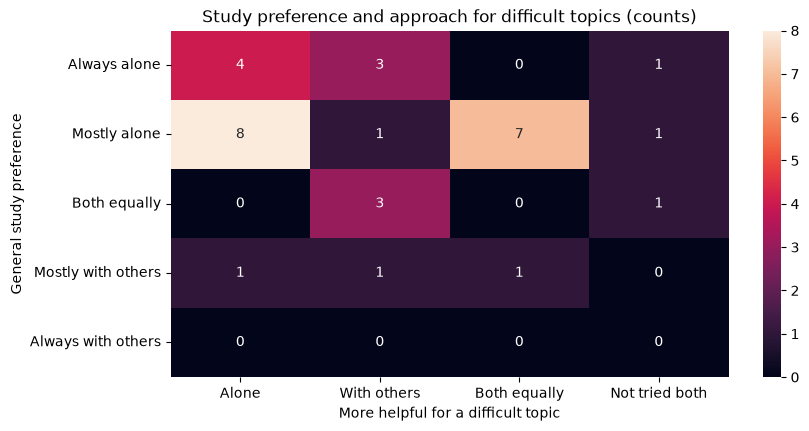

In [68]:
# Purpose: check if the general preference matches the approach for difficult topics
# dropna=False keeps "Always with others", so the rows match preference_short
chart_table = pd.crosstab(df["study_preference"], df["difficult_topic"], dropna=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(chart_table, annot=True, ax=ax)
ax.set_xticklabels(difficult_short, rotation=0)
ax.set_yticklabels(preference_short, rotation=0)
ax.set_title("Study preference and approach for difficult topics (counts)")
ax.set_xlabel("More helpful for a difficult topic")
ax.set_ylabel("General study preference")

fig.savefig(plot_file_name(6, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

## 8. Research question 4: digital learning resources


### 8.1 Video tutorials and written articles


In [69]:
# Both questions use the same scale, so we put them in one table
video_counts = df["video_use"].value_counts(sort=False)
article_counts = df["article_use"].value_counts(sort=False)

usage_counts = pd.DataFrame(
    {"Video tutorials": video_counts, "Blogs or articles": article_counts}
)
usage_counts

,Video tutorials,Blogs or articles
Never,0,6
Rarely (less than once a month),4,9
Sometimes (a few times a month),14,6
Often (weekly),10,7
Very often (several times a week or more),4,4


In [70]:
# Percentages of all respondents, the same denominator for both questions
usage_percent = usage_counts / n_responses * 100
usage_percent.round(1)

,Video tutorials,Blogs or articles
Never,0.0,18.8
Rarely (less than once a month),12.5,28.1
Sometimes (a few times a month),43.8,18.8
Often (weekly),31.2,21.9
Very often (several times a week or more),12.5,12.5


In [71]:
usage_percent.index.tolist()

['Never',
 'Rarely (less than once a month)',
 'Sometimes (a few times a month)',
 'Often (weekly)',
 'Very often (several times a week or more)']

In [72]:
# Short names for the charts, in the same order as the list above
frequency_short = [
    "Never",
    "Rarely\n< 1/month",
    "Sometimes\nfew/month",
    "Often\nweekly",
    "Very often\nseveral/week",
]

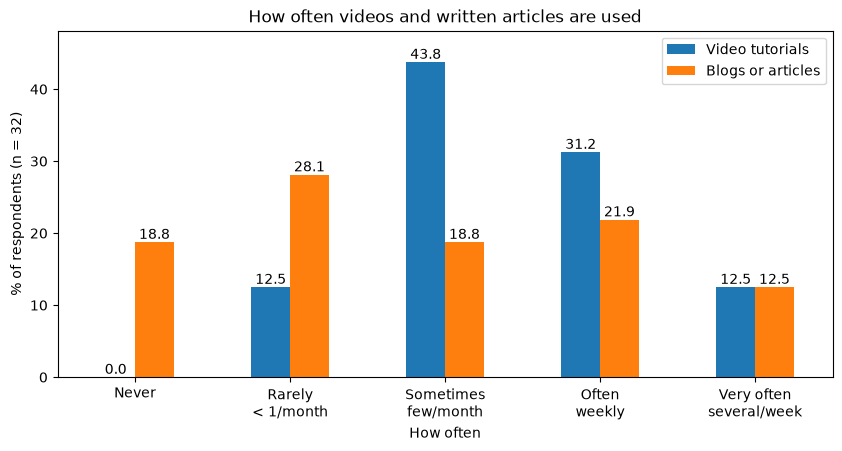

In [73]:
# Purpose: compare how often videos and written articles are used on the same scale
fig, ax = plt.subplots(figsize=(10, 4.5))
usage_percent.plot.bar(ax=ax, rot=0)
ax.set_xticklabels(frequency_short)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f")
ax.margins(y=0.1)
ax.set_title("How often videos and written articles are used")
ax.set_xlabel("How often")
ax.set_ylabel(f"% of respondents (n = {n_responses})")

fig.savefig(plot_file_name(7, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()

### 8.2 Preferred format for review


In [74]:
# This question measures preference, not how useful each format really is
review_counts = df["review_format"].value_counts(sort=False)
review_percent = df["review_format"].value_counts(sort=False, normalize=True) * 100

review_table = pd.DataFrame(
    {"count": review_counts, "percent": review_percent.round(1)}
)
review_table

,count,percent
review_format,,
Video tutorials,12,37.5
Blogs or written articles,4,12.5
Both equally,12,37.5
Neither (I use other resources),4,12.5


In [75]:
review_counts.index.tolist()

['Video tutorials',
 'Blogs or written articles',
 'Both equally',
 'Neither (I use other resources)']

In [76]:
# Short names for the charts, in the same order as the list above
review_short = [
    "Videos",
    "Blogs/articles",
    "Both equally",
    "Neither",
]

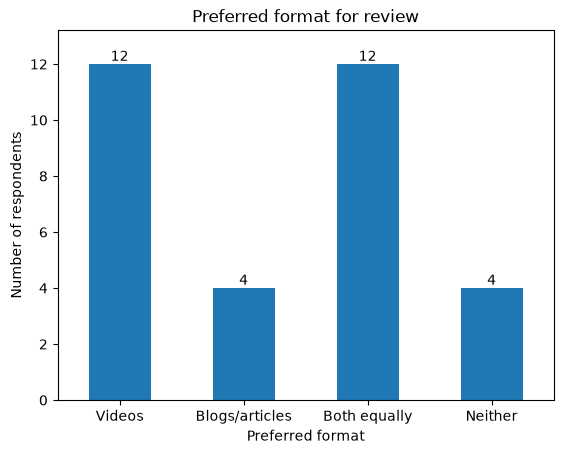

In [77]:
# Purpose: show which format respondents prefer when they review their learning
fig, ax = plt.subplots()
review_counts.plot.bar(ax=ax, rot=0)
ax.set_xticklabels(review_short)
ax.bar_label(ax.containers[0])
ax.margins(y=0.1)
ax.set_title("Preferred format for review")
ax.set_xlabel("Preferred format")
ax.set_ylabel("Number of respondents")

fig.savefig(plot_file_name(16, ax.get_title()), dpi=300, bbox_inches="tight")
plt.show()